In [1]:
import pandas as pd
import numpy as np      
import matplotlib.pyplot as plt 
import seaborn as sns 
import warnings
warnings.filterwarnings('ignore')   
import sklearn as sk 

from sklearn.model_selection import train_test_split 
from sklearn.model_selection import KFold
from sklearn.metrics import mutual_info_score 
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.feature_extraction import DictVectorizer 
from sklearn.metrics import roc_auc_score
from scipy.stats import chi2_contingency, pointbiserialr

In [2]:
import os 
os.getcwd()

df = pd.read_csv('../data/course_lead_scoring_2026.csv') 
print(df.head())

      lead_source       industry employment_status       location  \
0  organic_search     technology          employed         europe   
1    social_media     technology          employed  south_america   
2        referral         retail          employed         europe   
3        paid_ads  manufacturing           student            NaN   
4        referral  manufacturing           student  north_america   

   annual_income  number_of_courses_viewed  interaction_count  lead_score  \
0        88160.0                         3                  4        0.64   
1        72688.0                         3                  7        0.72   
2        44697.0                         3                  4        0.58   
3            NaN                         3                  6        0.57   
4        24062.0                         4                  5        0.62   

   converted  
0          1  
1          1  
2          1  
3          0  
4          1  


In [3]:
import sklearn
print(sklearn.__version__)

1.9.1


In [4]:
display(df.head())

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [5]:
df['lead_score'].nunique()

99

In [6]:
df['industry'].nunique()

6

In [7]:
df['employment_status'].nunique()

4

In [8]:
df['employment_status'].value_counts()

employment_status
employed         2633
student           760
self_employed     715
unemployed        698
Name: count, dtype: int64

In [9]:
df['lead_score'].nunique()
print(df['lead_score'].value_counts())

lead_score
0.46    114
0.48    112
0.47    104
0.53    104
0.60    104
       ... 
0.05      5
0.97      5
0.03      5
0.95      5
0.98      3
Name: count, Length: 99, dtype: int64


In [10]:
df.groupby('employment_status')['converted']==0


False

In [11]:
df['location'].nunique()

5

In [12]:
df.isnull().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [13]:
df.dtypes

lead_source                     str
industry                        str
employment_status               str
location                        str
annual_income               float64
number_of_courses_viewed      int64
interaction_count             int64
lead_score                  float64
converted                     int64
dtype: object

In [14]:
df.shape

(5000, 9)

In [15]:
display(df.describe())

,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
count,4631.000000,5000.000000,5000.000000,4965.000000,5000.000000
mean,54533.212049,2.089400,4.472600,0.494767,0.576600
std,21245.661710,1.188987,2.435906,0.199431,0.494147
min,12000.000000,0.000000,0.000000,0.010000,0.000000
25%,40458.500000,1.000000,3.000000,0.360000,0.000000
50%,55051.000000,2.000000,4.000000,0.490000,1.000000
75%,71252.500000,3.000000,6.000000,0.630000,1.000000
max,109886.000000,6.000000,13.000000,0.990000,1.000000


In [16]:
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   lead_source               4852 non-null   str    
 1   industry                  4760 non-null   str    
 2   employment_status         4806 non-null   str    
 3   location                  4792 non-null   str    
 4   annual_income             4631 non-null   float64
 5   number_of_courses_viewed  5000 non-null   int64  
 6   interaction_count         5000 non-null   int64  
 7   lead_score                4965 non-null   float64
 8   converted                 5000 non-null   int64  
dtypes: float64(2), int64(3), str(4)
memory usage: 351.7 KB
None


In [17]:
df.columns

Index(['lead_source', 'industry', 'employment_status', 'location',
       'annual_income', 'number_of_courses_viewed', 'interaction_count',
       'lead_score', 'converted'],
      dtype='str')

In [18]:
display(df.describe())

,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
count,4631.000000,5000.000000,5000.000000,4965.000000,5000.000000
mean,54533.212049,2.089400,4.472600,0.494767,0.576600
std,21245.661710,1.188987,2.435906,0.199431,0.494147
min,12000.000000,0.000000,0.000000,0.010000,0.000000
25%,40458.500000,1.000000,3.000000,0.360000,0.000000
50%,55051.000000,2.000000,4.000000,0.490000,1.000000
75%,71252.500000,3.000000,6.000000,0.630000,1.000000
max,109886.000000,6.000000,13.000000,0.990000,1.000000


In [19]:
cat_cols = ['lead_source', 'industry', 'employment_status', 'location']
df[cat_cols] = df[cat_cols].fillna('N/A')

num_cols = ['annual_income', 'lead_score']
df[num_cols] = df[num_cols].fillna(0)

<Axes: >

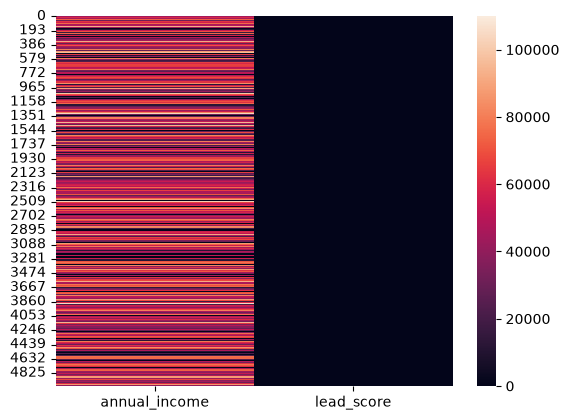

In [20]:
sns.heatmap(df[num_cols])

In [21]:
for col in cat_cols:
    #cat_cols_table =display(pd.crosstab(df[col], df['converted']))
    cat_cols_table = pd.crosstab(df[col], df['converted'])
    chi2, p, dof, expected = chi2_contingency(cat_cols_table)
    print(f"{col}: chi2={chi2:.4f}, p-value={p:.4g}")

lead_source: chi2=323.5422, p-value=8.658e-68
industry: chi2=22.8094, p-value=0.0008629
employment_status: chi2=227.9072, p-value=3.725e-48
location: chi2=10.6717, p-value=0.05829


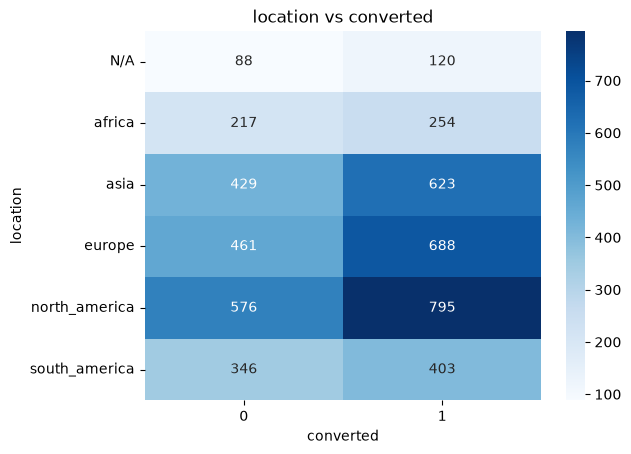

In [22]:
# col is a column name, not a matrix
heatmap_data = pd.crosstab(df[col], df['converted'])

sns.heatmap(heatmap_data, annot=True, cmap='Blues', fmt='d')
plt.title(f'{col} vs converted')
plt.show()

In [23]:
df.isnull().sum()

lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64

In [24]:
display(df.head())

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,N/A,0.0,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [25]:
df['industry'].value_counts()

industry
technology       1173
retail            925
healthcare        840
finance           720
education         639
manufacturing     463
N/A               240
Name: count, dtype: int64

In [26]:
df.columns = df.columns.str.strip().str.lower().str.replace(' ', '_').str.replace('(', '').str.replace(')', '') 
categorical_columns = df.select_dtypes(include=['object']).columns 

In [27]:
df.dtypes

lead_source                     str
industry                        str
employment_status               str
location                        str
annual_income               float64
number_of_courses_viewed      int64
interaction_count             int64
lead_score                  float64
converted                     int64
dtype: object

In [28]:
df['converted'].value_counts(normalize=True)

converted
1    0.5766
0    0.4234
Name: proportion, dtype: float64

In [29]:
df['converted'].mean()

np.float64(0.5766)

In [30]:
display(df.columns)

Index(['lead_source', 'industry', 'employment_status', 'location',
       'annual_income', 'number_of_courses_viewed', 'interaction_count',
       'lead_score', 'converted'],
      dtype='str')

Correlation Matrix of Numerical Features:


,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
annual_income,1.000000,0.161300,0.122842,0.229496,0.189652
number_of_courses_viewed,0.161300,1.000000,0.721609,0.757204,0.395038
interaction_count,0.122842,0.721609,1.000000,0.915746,0.448624
lead_score,0.229496,0.757204,0.915746,1.000000,0.483246
converted,0.189652,0.395038,0.448624,0.483246,1.000000


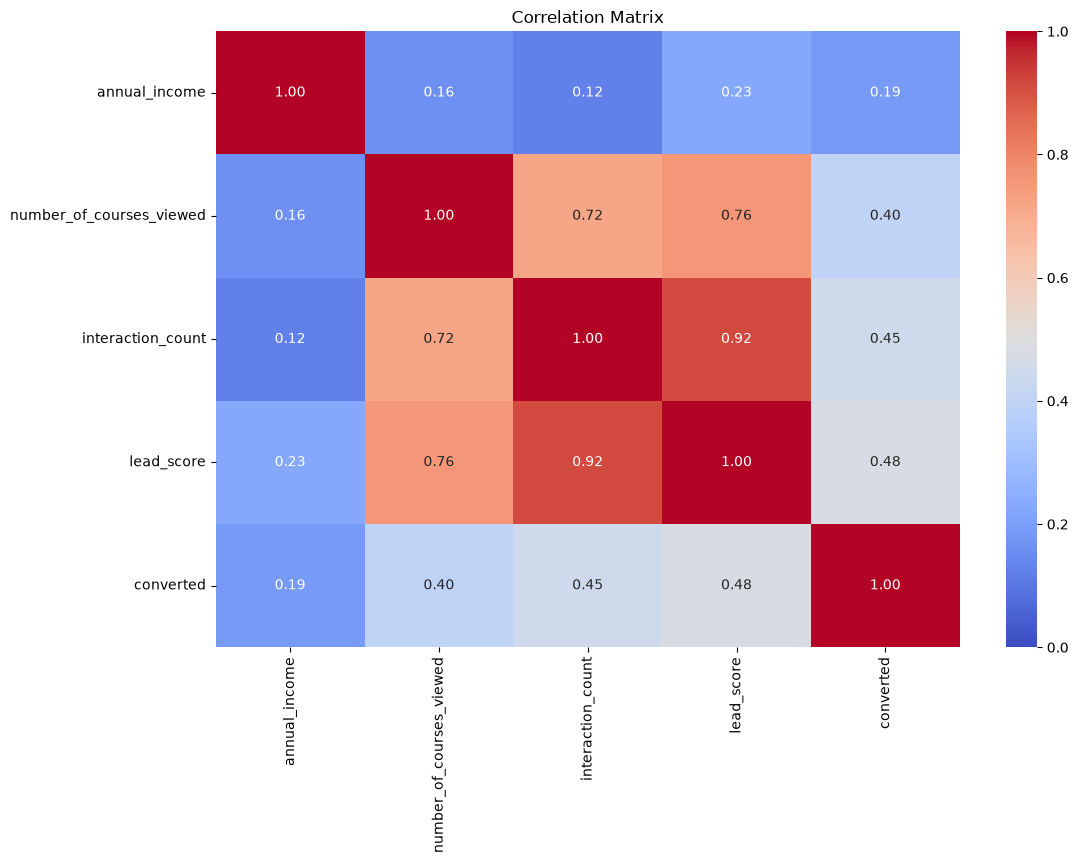

In [31]:
# Select only numerical features
numeric_df = df.select_dtypes(include=[np.number])

# Compute correlation coefficient for every pair of numerical features
corr_matrix = numeric_df.corr()

# Display the matrix
print('Correlation Matrix of Numerical Features:')
display(corr_matrix)

# Visualize the correlation matrix
plt.figure(figsize=(12, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', vmin=0, vmax=1, fmt='.2f')
plt.title('Correlation Matrix')
plt.show()


In [32]:
# num_df = df.select_dtypes(include=[np.number])

# corr_matrix = num_df.corr()

# # Display the matrix
# print('Correlation Matrix of Numerical Features:')
# display(corr_matrix)

# # Visualize the correlation matrix
# plt.figure(figsize=(12, 8))
# sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f')
# plt.title('Correlation Matrix')
# plt.show()

In [33]:
# X = df.drop(columns=['converted'])
# y = df['converted']

# X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# # Keep a validation split for later model tuning
# X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.25, random_state=42, stratify=y_train)

# model = LinearRegression()

# model.fit(X_train, y_train)

# print("Intercept:", model.intercept_)

# coefficients = pd.DataFrame({
#     "Feature": X.columns,
#     "Coefficient": model.coef_
# })

# print(coefficients)

In [34]:
X = df.drop(columns=['converted'])
y = df['converted']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Keep a validation split for later model tuning
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.25, random_state=42, stratify=y_train)

# One-hot encode categorical columns using the training split only
cat_cols = ['lead_source', 'industry', 'employment_status', 'location']
encoded_train = pd.get_dummies(X_train[cat_cols], columns=cat_cols)

# Mutual information for each one-hot encoded feature against the target
mi_scores = {col: mutual_info_score(y_train, encoded_train[col]) for col in encoded_train.columns}
mi_df = pd.DataFrame(
    {
        'feature': list(mi_scores.keys()),
        'mutual_information': list(mi_scores.values())
    }
).sort_values('mutual_information', ascending=False)

display(mi_df)

,feature,mutual_information
14,employment_status_employed,1.976608e-02
3,lead_source_paid_ads,1.326788e-02
4,lead_source_referral,1.322218e-02
17,employment_status_unemployed,1.045934e-02
1,lead_source_events,6.434106e-03
2,lead_source_organic_search,6.429931e-03
16,employment_status_student,6.222154e-03
12,industry_technology,1.625958e-03
7,industry_education,1.037004e-03
23,location_south_america,4.444566e-04


In [35]:
# One-hot encoded categorical features with target only from the training split
encoded_train = pd.get_dummies(X_train[cat_cols], columns=cat_cols)
mi_values = {col: mutual_info_score(y_train, encoded_train[col]) for col in encoded_train.columns}

mi_df_encoded = pd.DataFrame(
    {
        'feature': list(mi_values.keys()),
        'mutual_information': list(mi_values.values())
    }
).sort_values('mutual_information', ascending=False)

display(mi_df_encoded)

,feature,mutual_information
14,employment_status_employed,1.976608e-02
3,lead_source_paid_ads,1.326788e-02
4,lead_source_referral,1.322218e-02
17,employment_status_unemployed,1.045934e-02
1,lead_source_events,6.434106e-03
2,lead_source_organic_search,6.429931e-03
16,employment_status_student,6.222154e-03
12,industry_technology,1.625958e-03
7,industry_education,1.037004e-03
23,location_south_america,4.444566e-04


In [41]:
# Prepare data for modeling
for col in cat_cols:
    X_train[col] = X_train[col].fillna('N/A')
    X_val[col] = X_val[col].fillna('N/A')

for col in ['annual_income', 'lead_score']:
    median_value = X_train[col].median()
    X_train[col] = X_train[col].fillna(median_value)
    X_val[col] = X_val[col].fillna(median_value)

X_train_model = pd.get_dummies(X_train, columns=cat_cols)
X_val_model = pd.get_dummies(X_val, columns=cat_cols)
X_val_model = X_val_model.reindex(columns=X_train_model.columns, fill_value=0)

# Reproducible logistic regression model
model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000, random_state=42)
model.fit(X_train_model, y_train)

# Validation accuracy rounded to 2 decimal digits
val_accuracy = model.score(X_val_model, y_val)
print(round(val_accuracy, 2))

0.66


In [40]:
!uv --version

uv 0.12.11 (Homebrew 2026-09-08 aarch64-apple-darwin)


In [43]:
import pickle

In [44]:
from pathlib import Path

model_artifact = {
    "model": model,
    "feature_columns": X_train_model.columns.tolist(),
}
model_path = Path.cwd() / "lead_model.pkl"
with model_path.open("wb") as model_file:
    pickle.dump(model_artifact, model_file)

print(f"Saved model to: {model_path.resolve()}")

Saved model to: /Users/ashfaqohi/Machine_learning_models_exercise/4_classification/Notebooks /lead_model.pkl
